# In-Class Assignment: Linear Regression
# Day 13
# CMSE 202

### <p style="text-align: right;"> &#9989; **Christian Scheel** </p>
#### <p style="text-align: right;"> &#9989; Phadet, Cooper, Andie</p>


<img src="https://imgs.xkcd.com/comics/extrapolating.png" width=400px alt="xkcd comic 'Extrapolating': from two data points a figure draws a wildly runaway curve, joking about over-extrapolating from limited data.">

---
### Goals for today

After this assignment, you will be able to:
* plot a distribution of data
* construct and visualize the correlations between different variables in a data set
* use `statsmodels` to perform a linear regression 
* interpret the quality of the linear fit
* perform a linear regression from scratch

### How this connects to the course learning goals

Beyond today's goals, this assignment builds toward several **course-level learning goals** (CLG 1-7; see the syllabus or the Day 1 notebook):

* **CLG 5 - Manipulate, analyze, and visualize datasets:** you'll load and describe the real abalone dataset, build a correlation matrix + heatmap, and plot distributions and fits.
* **CLG 1 - Design and write programs to solve problems:** you'll perform a linear regression and then re-implement the least-squares fit (and R-squared / MSE) **from scratch**.
* **CLG 2 - Identify and use pre-existing tools:** you'll use `pandas`, `seaborn`, and `statsmodels` to load, visualize, and model the data.
* **CLG 7 - Communicate and explain your work in writing:** you'll interpret the fit quality, judge whether the linear-regression assumptions hold, and compare your from-scratch results to statsmodels.
* **CLG 6 - Work in diverse groups to develop scientific software:** you'll discuss choices (which variables, which fit) with your group throughout.
* **CLG 4 - Use modern software development tools:** Part 0 revisits the Git add/commit/push workflow.

### Agenda for today's class:

1. [Exploring unfamiliar data](#explore)
1. [Linear regression](#regression)
1. [Are we justified in using linear regression?](#justification)
1. [Building the fit from scratch](#scratch)

---
## Part 0: Revisiting Git

It's been a while since we have practiced with git. So, the agenda of this section is to revisit the concepts of Git by creating a new folder inside the cmse202-f26-turnin repository called Day-13 and adding this notebook.

So, for this ICA try:

1. Navigate to your cmse202-f26-turnin local repository.
2. Create a new directory called Day-13.
3. Add the ICA notebook into the new directory.
4. Commit the changes
5. Finally, push your changes to Github.


---
<a id="explore"></a>
## 1. Exploring unfamiliar data 
<img src="https://assets.montereybayaquarium.org/general/images/animals/invertebrates/juvenile-red-abalones-RW18-001.png" width=250px align="left" alt="A group of red abalone, a marine snail with a spiral shell edged with small respiratory holes. (Photo credit: Monterey Bay Aquarium.)" hspace="20" vspace="0">

Abalone are a class of marine snails that create a shell of "nacre" of increasing thickness over the course of their lifetime. A very good indication of the age of a particular abalone is the number of "rings" of nacre that have been deposited in the creation of the shell. We are going to look at a data set that is used to estimate the number of rings of a particular abalone shell based on various other abalone characteristics.  [You can read more about abalone here](https://www.montereybayaquarium.org/animals/animals-a-to-z/abalone).

On the course supplemental data repository, there are two files you'll need for this assignment. The first is `Dataset.data` which contains 4177 individual abalone measurements. The second is `Dataset.spec` which contains the labels for the 9 columns. 

Note a couple of things:
* The values in the data file are *space separated*. You should be able to load this data using Pandas.
* The first column is categorical (non-numeric) data. You can ignore it going forward.
* The final column, the count of `rings`, is the **dependent variable** that we will use.

**&#9989; Do This:**  To get started, **you'll need to download the following two files**:

`https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/main/data/Dataset.data`

`https://raw.githubusercontent.com/msu-cmse-courses/cmse202-supplemental-data/main/data/Dataset.spec`

### 1.1 Loading and describing the data

**&#9989; Do This:** Using `pandas`, load the data from the data file. You'll need to review the details in the Dataset.spec file to understand the structure of the data and the appropriate names for the columns. There's a bit of starter code include below to help you get started. You can use the `pd.read_csv()` function to load the data, and you will need to specify the appropriate arguments to ensure that the data is loaded correctly after you have the column names.

Once you've loaded the data, calculate and display the following concerning the `rings` data of the samples:
* the max
* the min
* the mean
* the median
* a histogram (using any tool you like) of the distribution of `rings` values

There's more than one way to do this -- you should discuss ideas for how to do with with your group!

In [38]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

sns.set_context("notebook")

# You need to set up a list of column names to use when loading the data. The Dataset.spec file provides the details for the column names and their order.
column_names = ["sex", "length", "diameter", "height", "whole_height", "shucked_weight", "viscera_weight", "shell_weight", "rings"]

# Once you have the column names, load the data using pandas. 
abalone = pd.read_csv("abalone-data", delimiter = " ", header=None) # Fill in the appropriate arguments to load the data with the correct column names.
abalone.columns = column_names
abalone.head()

,sex,length,diameter,height,whole_height,shucked_weight,viscera_weight,shell_weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [39]:
# Put your code here to print the summary statistics of the "rings" column in the abalone dataset and to make a histogram of the "rings" column. 
rings = abalone["rings"]
rings.describe()

count    4177.000000
mean        9.933684
std         3.224169
min         1.000000
25%         8.000000
50%         9.000000
75%        11.000000
max        29.000000
Name: rings, dtype: float64

### 1.2 - Looking at correlations between variables in your data

Let's make a [correlation](https://en.wikipedia.org/wiki/Correlation_and_dependence) matrix of the variables in the abalone dataset and plot it as a heat map. 

A `pandas` DataFrame has a built-in method that can provide a correlation matrix of the variables in the frame. The values show up as a matrix where the rows and columns are the column headers. The value in each cell is the correlation of that pair of values. The correlation values range from -1 to 1. 
* A correlation of 1 means that the two data elements are _perfectly_ positively correlated. As one goes up, so does the other in exact agreement. 
* A value of -1 means that as one goes up, the other goes down in exact agreement; this is _perfectly_ negatively correlated.
* A correlation value of 0 means there is no correlation. 
* Anything in between -1 and 1 gives the degree to which there is a positive or negative correlation between two variables.
The diagonal of the matrix is all ones since that the correlation of the column with itself.

**What is the `pandas` the method for producing a correlation matrix for a DataFrame?** 

**&#9989; Do This:** Calculate and display the correlation matrix associated with your data. NOTE: Depending on your pandas version, this step might initially give you an error. If this is the case, remove the sex column from the dataframe.

In [40]:
# put your code here
nosex = abalone.drop(columns = "sex")
corr = nosex.corr()
corr

,length,diameter,height,whole_height,shucked_weight,viscera_weight,shell_weight,rings
length,1.000000,0.986812,0.827554,0.925261,0.897914,0.903018,0.897706,0.556720
diameter,0.986812,1.000000,0.833684,0.925452,0.893162,0.899724,0.905330,0.574660
height,0.827554,0.833684,1.000000,0.819221,0.774972,0.798319,0.817338,0.557467
whole_height,0.925261,0.925452,0.819221,1.000000,0.969405,0.966375,0.955355,0.540390
shucked_weight,0.897914,0.893162,0.774972,0.969405,1.000000,0.931961,0.882617,0.420884
viscera_weight,0.903018,0.899724,0.798319,0.966375,0.931961,1.000000,0.907656,0.503819
shell_weight,0.897706,0.905330,0.817338,0.955355,0.882617,0.907656,1.000000,0.627574
rings,0.556720,0.574660,0.557467,0.540390,0.420884,0.503819,0.627574,1.000000


**&#9989; Questions:** What do you notice? Can you find variables that correlate strongly with the number of rings? What might make finding these variables easier?

<font size=+3>&#9998;</font> Shell weight and viscera_weight, diameter and length, whole_height and length.

The tools `seaborn` is useful for visualization. You can display a [heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html), a color for each cell, of a correlation matrix. It gives a visual clue as to what data elements are correlated.

**&#9989; Do this:** Generate a heatmap for the correlation matrix from above and plot it onto the given figure and axis.

<Axes: >

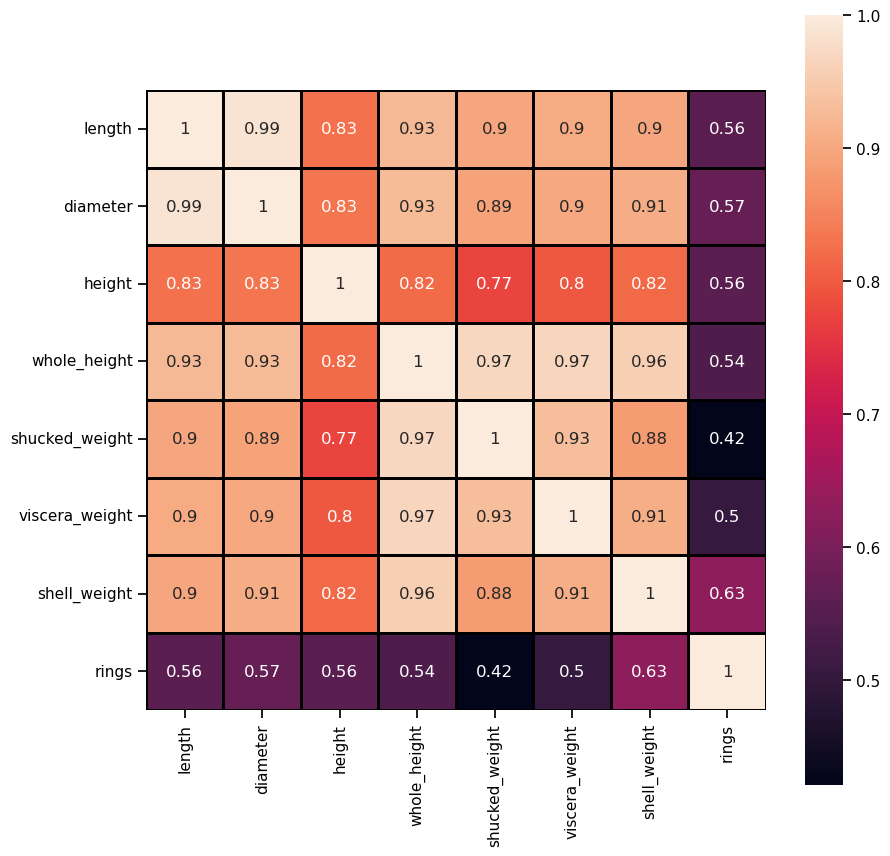

In [41]:
fig, ax = plt.subplots(1,1, figsize = (10,10) )
# put your code here
sns.heatmap(corr, square = True, annot = True, linewidths = 1, linecolor = "black")

**&#9989; Questions:** What do you notice? Can you find variables that correlate strongly with the number of rings and do they agree with what you found by examining the correlation matrix? What makes this a better representation of your data than simply the matrix above?

<font size=+3>&#9998;</font> Items that have strong correlation have a lighter color

---
<a id="regression"></a>
## 2. Linear Regression

Looking at our heatmap, select the independent variable that has the best correlation with the dependent variable `rings`.

**&#9989; Do this:** Write in the cell below what variable you will work with below.

<font size=+3>&#9998;</font> Shell weight has the highest correlation value

### 2.1 Perform the regression using `statsmodels`

Having selected an independent variable, let us do a linear regression using your selected variable (let's just call it `x`) and the `rings` variable (let's just call that `y`). Using what you reviewed in your pre-class assignment, we'll used `statsmodels` for this. 


**&#9989; Do this:** Using `statsmodels`, perform a linear regression to predict the number of rings using the indepdent variable you selected. **Print the slope and the intercept for your model.**

_Look to the pre-class assignment for some hints and check in with your group._

In [86]:
# put your code here
import statsmodels.api as sm

rings = abalone["rings"]
shell_w = abalone["shell_weight"]

x_with_cnst = sm.add_constant(rings)

model = sm.OLS(shell_w, x_with_cnst)
results = model.fit()


### 2.2 Print statistics

While this model has provided the slope and intercept for the fit, it has not suggested how well the model fits our data. Luckily, the results produced by the `fit()` method can provide a summary.

**&#9989; Do this:** Print the statistics associated with your fit. Comment below that on how well the fit is for the data.

In [82]:
# put your code here
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           shell_weight   R-squared:                       0.394
Model:                            OLS   Adj. R-squared:                  0.394
Method:                 Least Squares   F-statistic:                     2713.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:46:58   Log-Likelihood:                 3355.5
No. Observations:                4177   AIC:                            -6707.
Df Residuals:                    4175   BIC:                            -6694.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0303      0.005     -5.582      0.000      -0.041      -0.020
rings          0.0271      0.001     52.084      0.000       0.026       0.028
==============================================================================
Omnibus:                      251.891   Durbin-Watson:                   0.685
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              338.428
Skew:                           0.551   Prob(JB):                     3.24e-74
Kurtosis:                       3.856   Cond. No.                         34.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

**&#9989; Do this:** Comment on the fit of your model. What are you using to judge the fit?

<font size=+3>&#9998;</font> Based off of the r-squared value, it does not fit the data that well as it is 0.394

### 2.3 Visualizaton

Mathematically, any data can be fit to a line. Whether a line is a good model to use to fit that data depends on a number of issues. One of the more famous examples of data being fit to a line where that data has precisely the same fit, but wildly different data is [Anscombe's quartet](https://en.wikipedia.org/wiki/Anscombe%27s_quartet). The main figure is reproduced below:

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/e/ec/Anscombe%27s_quartet_3.svg/500px-Anscombe%27s_quartet_3.svg.png" width=500px alt="Anscombe's quartet: four scatter plots with identical linear-regression fits and summary statistics but very different data patterns.">

You can see that each data set is different, but the mathematical model that fits each of these data sets is the same! You must be careful that your data do not violate one or more of the [underlying assumptions of linear fitting](https://en.wikipedia.org/wiki/Linear_regression#Assumptions). This is one reason it is incredibly important to visualize your data and the model that fits it.

**&#9989; Question:** For the four plots above, which would you find believable? That is, which ones are reasonable fits to the data and why?

<font size=+3>&#9998;</font> x1 and y1 because it visually fits that data the best

**&#9989; Do this:** Plot the scatter plot of your independent and dependent data and also plot the line predicted by the regression.

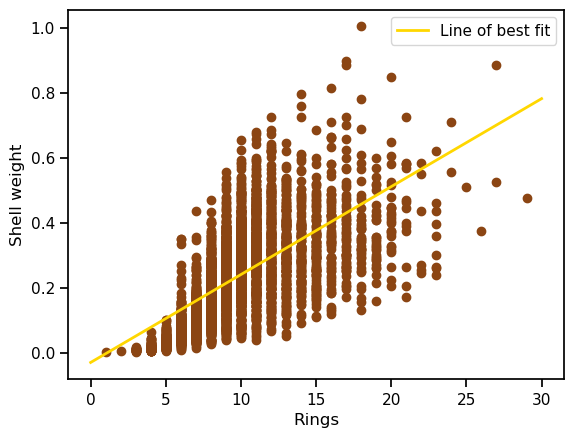

In [103]:
# put your code here

plt.scatter(rings, shell_w, color = "saddlebrown")
plt.xlabel("Rings")
plt.ylabel("Shell weight")

slope = results.params['rings']
y_int = results.params['const']

x_ary = np.arange(0,30.5,0.5)
y_ary = (slope) * x_ary + y_int

plt.plot(x_ary, y_ary, color = "gold", label = "Line of best fit", linewidth = 2)
plt.legend()

**&#9989; Do this:** How well does your model fit your data? Look back at the measure you used to judge the fit initially, what more information do you gain from plotting the data and the fit? Would you say that you had a good model of your data? What might make your model better?

<font size=+3>&#9998;</font> This model would fit the data better if it were an exponential representation

<div class="alert alert-block alert-info"> 

_Thinking carefully about what model we use to fit data is important, as is how we judge the quality of our models and the fits we come up with. We'll have more opportunities to discuss this in future assignments as well._

Additionally, *visualizing our data before just calculating a fit or looking for a correlation is important*. It can help us understand the data and the relationships between variables, and it can also help us identify potential issues with our models.

In the case of this assignment, a scatter matrix of the data alongside a correlation matrix/heatmap can be very useful in understanding the relationships between variables.
</div>

---
<a id="justification"></a>
## 3. Are we justified in using linear regression?

One of the critical assumptions of linear regression is that of ["constant variance"](https://en.wikipedia.org/wiki/Linear_regression#Assumptions). This means that the different values of the dependent variable have the same variance in their errors, regardless of the value of the independent variable. This is typically checked using a residual plot, which is available using `plot_regress_exog`. If the distribution of residuals (a proxy for the errors) is evenly distributed, we can feel more confident that we were justified in using linear regression.

**&#9989; Do this:** Use `plot_regress_exog` to investigate the distribution of residuals in your model fit. Make sure to create a large enough figure so that everything is easily visible


In [105]:
sm.regressionplots.plot_regress_exog(results)

AttributeError: module 'statsmodels.api' has no attribute 'regressionplots'

In [95]:
# put your code here
fig = plt.figure(figsize=(15, 6))


<Figure size 1500x600 with 0 Axes>

**&#9989; Questions:** Does it appear you were justified in using linear regression? Why or why not? _If it helps, you might look back at the same plot you made for the `noisy` data in the pre-class assignment._

<font size=+3>&#9998;</font> The data does not fit well

**&#9989; Questions:**  You might also be able to tell if your linear model overpredicts or underpredicts the number of rings with this model for certain values of your independent variable. Can you? If so, does it over/under-predict?

<font size=+3>&#9998;</font> Do this - Erase this and put your answer here.

---
<a id="scratch"></a>
## 4. Building the fit from scratch

The `statsmodels` library is quite powerful and has a number of tools that we will use to fit data. But in the simplest fit it can do, a linear model of one variable, what is the library doing? You will perform the calculations yourself below to try construct the same fit to your data.


### 4.1 Performing a Least Squares fit

Let's do some of that work ourselves to see if we can reproduce those results. We are going do the math for linear regression ourselves and see if our math agrees with the tools we used above. Below is the math. We'll use the same independent and dependent variables that you chose above.

Let's assume that the symbols $\bar{x}$ and $\bar{y}$ represent the means of those arrays and that `n` is the number of elements.

Here's the calculation for the slope for a single variable linear model:
$$ slope = \frac {\sum_{i=1}^{n}{(x_i - \bar{x}) * (y_i - \bar{y}) } } {\sum_{i=1}^{n}{(x_i - \bar{x})^2}}$$

Here's the calculation for the intercept for a single variable linear model:
$$ intercept = \bar{y} - slope*\bar{x} $$

**&#9989; Do this:** Using the same independent variable and the same dependent variable as above, calculate the slope and intercept of the best fit least squares using the formula provided. Print the slope and the intercept.

In [ ]:
# put your code here


**&#9989; Question:** How well do your slope and intercept agree with the results from `statsmodels`?

<font size=+3>&#9998;</font> Do this - Erase this and put your answer here.

**&#9989; Do this:**  Plot the same scatter plot for your data you used above and plot the new regression line through that data using your **calculated slope and intercept**.

In [ ]:
# put your code here


### 4.2 Coefficient of Determination and Mean-Squared Error

We will now calculate the [coefficient of determination ($R^2$)](https://en.wikipedia.org/wiki/Coefficient_of_determination) and the mean-squared error (MSE). These results are also produced by `statsmodels` in its summary statistics.

The coefficient of determination calculations are as follows:

Total sum of squares is:
$$ tsum = \sum_{i=1}^{n}{(y_i - \bar{y})^{2}} $$

The sum of the squares of the residuals (also called the residual sum of squares) is:
$$ residual = \sum_{i=1}^{n}{(y_i - y_{predicted})}^{2} $$

Mean-squared error is just $$ MSE = \frac{1}{n} * residual$$ or $$ MSE = \frac{1}{n}\sum_{i=1}^{n}{(y_i - y_{predicted})}^{2} $$

The coefficient of determination ($R^2$) is:
$$ cod = R^2 =  1 - \frac{residual}{tsum} $$

**&#9989; Do this:**  Using the same data you used above, develop a new array `y_predict`  based on your **calculated slope and intercept**. Provide the coefficient of determination and mean-squared error of your calculated regression model.

In [ ]:
# put your code here


**&#9989; Question:** How well do your results agree with the results from `statsmodels`?

<font size=+3>&#9998;</font> Do this - Erase this and put your answer here.

---
### &#128721; STOP
**Commit your changes to your Git repository!**

Take a moment to save your notebook, commit  and push the changes to your Git repository.


-----
### Congratulations, you're done with your in-class assignment!

Now, you just need to submit this assignment by uploading it to the course <a href="https://d2l.msu.edu/">Desire2Learn</a> web page for today's submission folder (Don't forget to add your names in the first cell).

&#169; Copyright 2026, The Department of Computational Mathematics, Science and Engineering at Michigan State University.